# Practical	work n°1 : Introduction	to Image Processing and Analysis

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### 1. Histogram construction/manipulation for luminance correction

In [6]:
chemin_image = r"C:\Users\USER\OneDrive\Bureau\traitement d'image\dark_lena.png"

In [8]:
dark_lena = cv2.imread(chemin_image, cv2.IMREAD_GRAYSCALE)

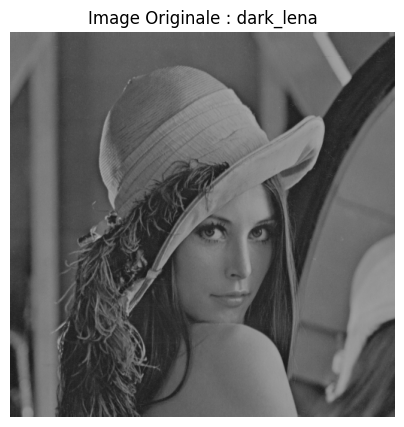

In [10]:
plt.figure(figsize=(5, 5))
plt.imshow(dark_lena, cmap='gray', vmin=0, vmax=255)
plt.title('Image Originale : dark_lena')
plt.axis('off')
plt.show()

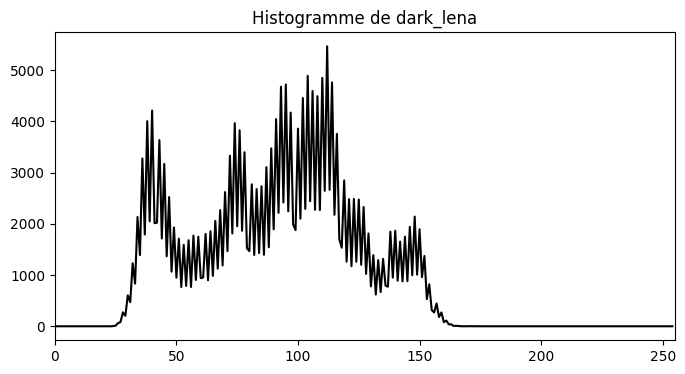

In [12]:
hist_dark, bins_dark = np.histogram(dark_lena.flatten(), 255, [0, 256])

plt.figure(figsize=(8, 4))
plt.plot(hist_dark, color='black')
plt.title('Histogramme de dark_lena')
plt.xlim([0, 255])
plt.show()

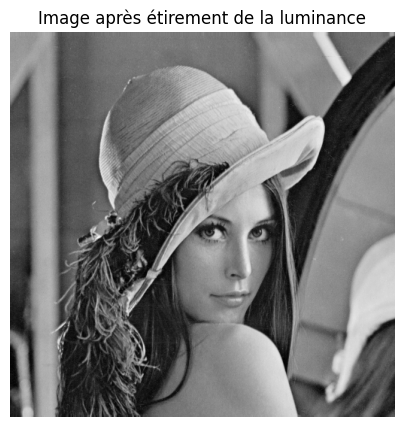

In [14]:
min_val = np.min(dark_lena)
max_val = np.max(dark_lena)

# Formule d'étirement
stretched_lena = ((dark_lena - min_val) / (max_val - min_val) * 255).astype(np.uint8)

plt.figure(figsize=(5, 5))
plt.imshow(stretched_lena, cmap='gray', vmin=0, vmax=255)
plt.title('Image après étirement de la luminance')
plt.axis('off')
plt.show()

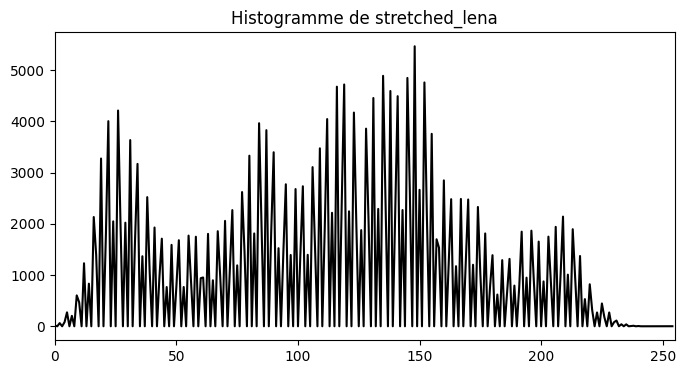

In [16]:
hist_dark, bins_dark = np.histogram(stretched_lena.flatten(), 255, [0, 256])

plt.figure(figsize=(8, 4))
plt.plot(hist_dark, color='black')
plt.title('Histogramme de stretched_lena')
plt.xlim([0, 255])
plt.show()

### 2. Histogram construction/manipulation for contrast correction

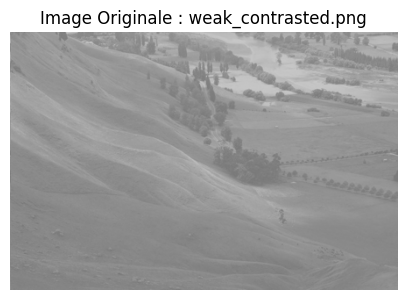

In [18]:
weak_cont = cv2.imread('weak_contrasted.png', cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(5, 5))
plt.imshow(weak_cont, cmap='gray', vmin=0, vmax=255)
plt.title('Image Originale : weak_contrasted.png')
plt.axis('off')
plt.show()

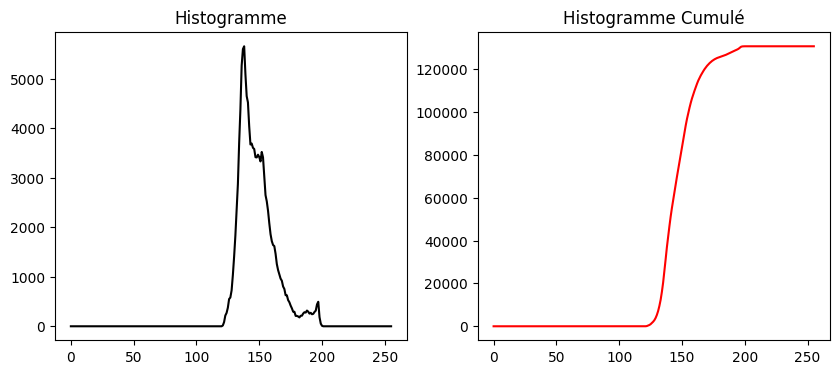

In [20]:
hist_wc, bins_wc = np.histogram(weak_cont.flatten(), 256, [0, 256])
cum_hist_wc = hist_wc.cumsum()

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_wc, color='black')
plt.title('Histogramme')

plt.subplot(1, 2, 2)
plt.plot(cum_hist_wc, color='red')
plt.title('Histogramme Cumulé')
plt.show()

In [22]:
total_pixels = weak_cont.shape[0] * weak_cont.shape[1]

cum_hist_normalized = (cum_hist_wc / total_pixels) * 255

lut = np.uint8(cum_hist_normalized)

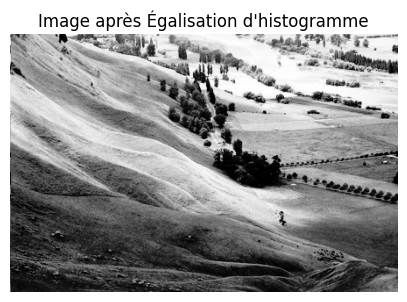

In [24]:
equalized_img = lut[weak_cont]

plt.figure(figsize=(5, 5))
plt.imshow(equalized_img, cmap='gray', vmin=0, vmax=255)
plt.title('Image après Égalisation d\'histogramme')
plt.axis('off')
plt.show()

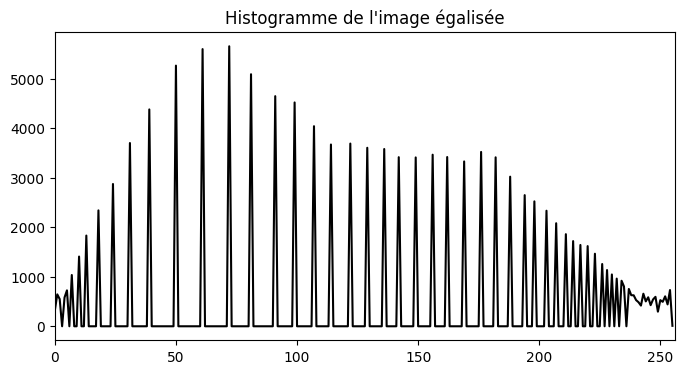

In [26]:
hist_eq, _ = np.histogram(equalized_img.flatten(), 256, [0, 256])

plt.figure(figsize=(8, 4))
plt.plot(hist_eq, color='black')
plt.title('Histogramme de l\'image égalisée')
plt.xlim([0, 256])
plt.show()

### 3. Histogram construction/manipulation for colored contrast correction

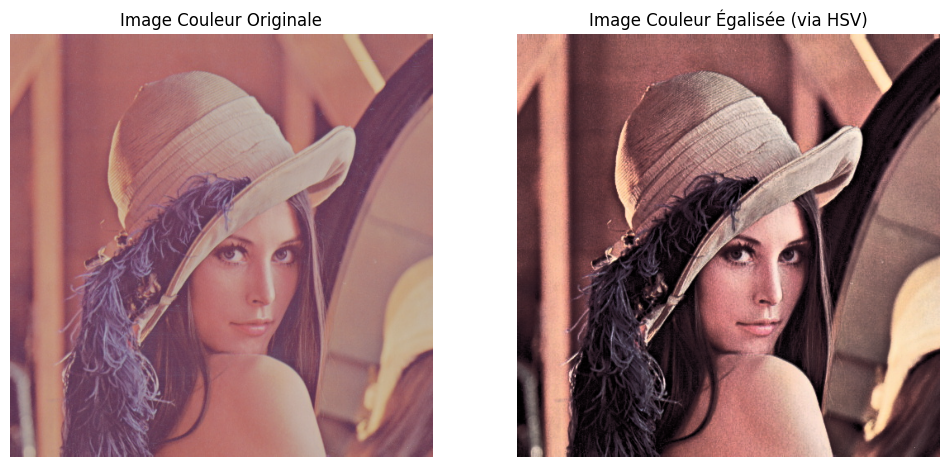

In [28]:
color_img_bgr = cv2.imread('weak_colored_contrast.png')

color_img_rgb = cv2.cvtColor(color_img_bgr, cv2.COLOR_BGR2RGB)

hsv_img = cv2.cvtColor(color_img_rgb, cv2.COLOR_RGB2HSV)

H, S, V = cv2.split(hsv_img)

V_equalized = cv2.equalizeHist(V)

hsv_img_eq = cv2.merge([H, S, V_equalized])

final_color_img = cv2.cvtColor(hsv_img_eq, cv2.COLOR_HSV2RGB)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(color_img_rgb)
plt.title('Image Couleur Originale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(final_color_img)
plt.title('Image Couleur Égalisée (via HSV)')
plt.axis('off')
plt.show()